Working on building the model for the exercise 1 (Arm Abduction).

In [1]:
path = '/kaggle/input/datasets/almutalem/rehab24-6-2d-30fps-repetition-extracted/processed_repetitions/2d_joints/Ex1'

In [2]:
import re
import os

FNAME_RE = re.compile(r"PM_(\w+?)_rep(\d+)_label(\d)\.npy")

def build_records(exercise_dir):
    records = []
    for fname in os.listdir(exercise_dir):
        m = FNAME_RE.match(fname)
        if not m:
            continue
        person, rep, label = m.group(1), int(m.group(2)), int(m.group(3))
        records.append({
            "path": os.path.join(exercise_dir, fname),
            "person_id": person,
            "rep": rep,
            "label": label,
        })
    return records

In [3]:
import numpy as np
from sklearn.model_selection import train_test_split
from collections import defaultdict

def subject_split(records, test_size=0.8, seed=42):
    """Person-disjoint train/test split, deterministic, percentage-based"""
    
    persons = sorted({r["person_id"] for r in records})
    per_person = defaultdict(list)
    for r in records:
        per_person[r["person_id"]].append(r["label"])

    flawed_share = np.array([1.0 - (sum(per_person[p]) / len(per_person[p])) for p in persons])
    strata = np.digitize(flawed_share, [0.001, 0.25, 0.75, 0.999])
    persons_arr = np.array(persons)
    strata_arr  = np.array(strata)

    try:
        train_persons, test_persons = train_test_split(
            persons_arr,
            test_size=test_size,
            random_state=seed,
            stratify=strata_arr,
            shuffle=True,
        )
    except ValueError:
        # small subject pools: some bucket may have only 1 person -> retry bare
        train_persons, test_persons = train_test_split(
            persons_arr,
            test_size=test_size,
            random_state=seed,
            shuffle=True,
        )

    train_set = set(train_persons.tolist())
    train = [r for r in records if r["person_id"] in train_set]
    test  = [r for r in records if r["person_id"] not in train_set]

    print(f"[split seed={seed} test_size={test_size}] "
          f"train={len(train_set)} persons, test={len(test_persons)} persons | "
          f"train reps P={sum(r['label'] for r in train)}, "
          f"test reps P={sum(r['label'] for r in test)}")
    return train, test

In [4]:
records = build_records(path)
train, test = subject_split(records, 0.2, 42)

[split seed=42 test_size=0.2] train=9 persons, test=3 persons | train reps P=56, test reps P=24


In [5]:
JN = {
    "Hips": 0, 
    "Spine": 1, 
    "Spine1": 2, 
    "Neck": 3, 
    "Head": 4, 
    "Head_end": 5,
    "LeftShoulder": 6, 
    "LeftArm": 7, 
    "LeftForeArm": 8, 
    "LeftHand": 9,
    "LeftHand_end": 10,
    "RightShoulder": 11, 
    "RightArm": 12, 
    "RightForeArm": 13, 
    "RightHand": 14,
    "RightHand_end": 15,
    "LeftUpLeg": 16, 
    "LeftLeg": 17, 
    "LeftFoot": 18, 
    "LeftToeBase": 19,
    "LeftToeBase_end": 20,
    "RightUpLeg": 21,
    "RightLeg": 22, 
    "RightFoot": 23, 
    "RightToeBase": 24,
    "RightToeBase_end": 25
}

g = lambda s, name: s[:, JN[name], :]

In [6]:
# Upper-body bone edges — the Ex1 mask. The AE only gets features from these
# joints, so it never wastes latent capacity modelling legs for an arm exercise.
UPPER_BONES = [(0, 1), (1, 2), (2, 3), (3, 4),          # spine chain
               (6, 7), (7, 8), (8, 9),                  # left arm chain
               (11, 12), (12, 13), (13, 14),            # right arm chain
               (0, 6), (0, 11), (1, 6), (1, 11)]

LEG_BONES = [(0, 16), (0, 21),                       # pelvis -> thighs
             (16, 17), (17, 18), (18, 19),           # left leg chain
             (21, 22), (22, 23), (23, 24),           # right leg chain
             (19, 20), (24, 25)]                     # toe tips

HEAD_TIP  = [(4, 5), (9, 10), (14, 15)]              # arrows/tips handled anyway

FULL_BONES = UPPER_BONES + LEG_BONES + HEAD_TIP

In [7]:
from dataclasses import dataclass

@dataclass
class Ex1Config:
    n_frames: int = 90          # resampled rep length
    sgf_win: int = 11           # savgol window
    sgf_poly: int = 2

    # -- feature toggles (each one is a named channel-group) ----------------
    use_angles: bool = True                 # joint angles in degrees
    use_bone_vectors: bool = True           # normalized bone end-to-start vectors (x,y)
    use_arm_positions: bool = True          # normalized (x,y) of the 6 arm-chain joints
    use_angular_velocity: bool = True       # d(angle)/dframe
    use_angular_accel: bool = False         # d2(angle)/dframe2 (off by default)
    use_joint_speed: bool = False           # |d(pos)/dframe| of arm joints (off by default)

    # -- normalization ------------------------------------------------------
    use_mirror_canonicalization: bool = True
    torso_eps: float = 1e-6

    # -- angle definitions for Ex1 ------------------------------------------
    #   (proximal, vertex, distal) in joint names
    angle_defs: tuple = (
        ("Neck", "LeftShoulder", "LeftArm"),           # arm elevation L
        ("Neck", "RightShoulder", "RightArm"),         # arm elevation R
        ("LeftShoulder", "LeftArm", "LeftForeArm"),    # elbow L
        ("RightShoulder", "RightArm", "RightForeArm"), # elbow R
        ("LeftArm", "LeftForeArm", "LeftHand"),        # wrist droop L
        ("RightArm", "RightForeArm", "RightHand"),     # wrist droop R
        ("Hips", "Spine1", "Neck"),                    # torso lean
    )
    # the arm-chain joints whose normalized positions can be fed raw-ish
    arm_position_joints: tuple = ("LeftArm", "LeftForeArm", "LeftHand",
                                  "RightArm", "RightForeArm", "RightHand")


CFG = Ex1Config()

### NORMALIZERS  (canonical -> spatial -> smooth -> resample)

In [8]:
def mirror_x(seq: np.ndarray) -> np.ndarray:
    """Mirror about the pelvis vertical axis. seq: (T,26,2)."""
    pelvis_x = seq[:, JN["Hips"], 0:1]
    out = seq.copy()
    out[:, :, 0] = 2.0 * pelvis_x - out[:, :, 0]
    return out


def canonicalize(seq: np.ndarray, is_mirror_rep: bool, cfg: Ex1Config = CFG) -> np.ndarray:
    """Left/right canonicalization. is_mirror_rep comes from the dataset metadata."""
    if cfg.use_mirror_canonicalization and is_mirror_rep:
        return mirror_x(seq)
    return seq.copy()

In [9]:
def spatial_normalize(seq: np.ndarray, cfg: Ex1Config = CFG) -> np.ndarray:
    """
    Per-frame: translate Hips to (0,0), divide by torso length |Spine - Hips|.
    Result is scale- and location-free ('torso-length units').
    Safe against degenerate frames (torso length ~ 0) via epsilon guard.
    """
    out = seq.copy() - seq[:, JN["Hips"], :][:, None, :]
    a = seq[:, JN["Hips"], :]
    b = seq[:, JN["Spine"], :]
    tl = np.linalg.norm(b - a, axis=-1)
    tl = np.maximum(tl, cfg.torso_eps)
    return out / tl[:, None, None]

In [10]:
from scipy.signal import savgol_filter
    
def smooth(seq: np.ndarray, cfg: Ex1Config = CFG) -> np.ndarray:
    """Savgol along time. Falls back to a small moving average without scipy."""
    T = seq.shape[0]
    win = min(cfg.sgf_win if cfg.sgf_win % 2 == 1 else cfg.sgf_win + 1, (T // 2) * 2 + 1)
    if win < 5:
        return seq
    
    return np.stack([savgol_filter(seq[:, j, :], win, cfg.sgf_poly, axis=0)
                         for j in range(seq.shape[1])], axis=1)

In [11]:
def resample(seq: np.ndarray, n: int = None) -> np.ndarray:
    """Linear interp of every (joint, channel) curve to fixed length n."""
    n = CFG.n_frames if n is None else n
    T = seq.shape[0]
    if T == n:
        return seq.copy()
    xs = np.arange(T)
    xd = np.linspace(0, T - 1, n)
    return np.stack([np.stack([np.interp(xd, xs, seq[:, j, c]) for c in range(2)],
                               axis=-1) for j in range(seq.shape[1])], axis=1)

### Feature Extractors

In [12]:
def angle_abc(a, b, c):
    """Angle at vertex b (degrees). a,b,c: (T,2). Vectorized over time."""
    ab, bc = a - b, c - b
    denom = (np.linalg.norm(ab, axis=-1) *
             np.linalg.norm(bc, axis=-1)) + 1e-9
    return np.degrees(np.arccos(np.clip(np.sum(ab * bc, axis=-1) / denom, -1, 1)))


def angle_channels(seq: np.ndarray, cfg: Ex1Config = CFG):
    """Angles per frame from cfg.angle_defs. Returns (T,K) and names."""
    feats, names = [], []
    for (p, v, d) in cfg.angle_defs:
        feats.append(angle_abc(g(seq, p), g(seq, v), g(seq, d)))
        names.append(f"ang_{v}")
    # shoulder-line tilt vs horizontal (signed, degrees) — free & useful for Ex1
    sh = g(seq, "RightShoulder") - g(seq, "LeftShoulder")
    feats.append(np.degrees(np.arctan2(sh[:, 1], sh[:, 0])))
    names.append("ang_shoulder_tilt")
    return np.stack(feats, axis=1), names


def bone_channels(seq, cfg: Ex1Config = CFG):
    """Normalized bone vectors (end - start), 2 channels per edge. (T,E*2)."""
    feats, names = [], []
    for (s, e) in UPPER_BONES:
        v = seq[:, e, :] - seq[:, s, :]
        feats.append(v[:, 0]); names.append(f"bone_{s}_{e}_x")
        feats.append(v[:, 1]); names.append(f"bone_{s}_{e}_y")
    return np.stack(feats, axis=1), names


def arm_position_channels(seq, cfg: Ex1Config = CFG):
    """Torso-normalized (x,y) of the arm-chain joints. (T,J*2)."""
    feats, names = [], []
    for name in cfg.arm_position_joints:
        p = g(seq, name)
        feats.append(p[:, 0]); names.append(f"pos_{name}_x")
        feats.append(p[:, 1]); names.append(f"pos_{name}_y")
    return np.stack(feats, axis=1), names


def kinematic_channels(angles: np.ndarray, seq: np.ndarray,
                       cfg: Ex1Config = CFG):
    """Temporal derivatives measured on the resampled curves -> same length."""
    feats, names = [], []
    if cfg.use_angular_velocity:
        feats.append(np.gradient(angles, axis=0))
        names += [f"dang_{i}" for i in range(angles.shape[1])]
    if cfg.use_angular_accel:
        feats.append(np.gradient(angles, axis=0, edge_order=2)
                     if angles.shape[0] > 2 else np.zeros_like(angles))
        names += [f"d2ang_{i}" for i in range(angles.shape[1])]
    if cfg.use_joint_speed:
        v = np.gradient(seq, axis=0)                       # (T,26,2) frame-derivative
        speeds = np.linalg.norm(v, axis=-1)                # (T,26)
        sel = [JN[n] for n in cfg.arm_position_joints]
        feats.append(speeds[:, sel])
        names += [f"speed_{cfg.arm_position_joints[i]}" for i in range(len(sel))]
    if not feats:
        return np.zeros((angles.shape[0], 0)), []
    return np.concatenate(feats, axis=1), names

### PER-REP Pipeline

In [13]:
def build_rep(coord: np.ndarray, is_mirror_rep: bool = False,
              cfg: Ex1Config = CFG, return_template: bool = True) -> dict:
    """
    One rep -> dict with:
      X        (n_frames, D)   float32 feature matrix   [model input]
      template (n_frames,26,2)  torso-normalized skeleton [ghost overlay fuel]
      names    list of D feature names
    """
    x = np.asarray(coord, dtype=np.float64)

    x = canonicalize(x, is_mirror_rep, cfg)
    x = spatial_normalize(x, cfg)          # geometric norm (before smoothing)
    x_s = smooth(x, cfg)
    x_r = resample(x_s, cfg.n_frames)

    blocks, blk_names = [], []
    if cfg.use_angles:
        a, n = angle_channels(x_r, cfg)
        blocks.append(a); blk_names += n
        kin, kn = kinematic_channels(a, x_r, cfg)   # kinematics hang off angles
        blocks.append(kin); blk_names += kn
    if cfg.use_bone_vectors:
        b, n = bone_channels(x_r, cfg)
        blocks.append(b); blk_names += n
    if cfg.use_arm_positions:
        p, n = arm_position_channels(x_r, cfg)
        blocks.append(p); blk_names += n

    if not blk_names:
        raise ValueError("no feature channels enabled in Ex1Config")

    X = np.concatenate(blocks, axis=1)
    if not np.isfinite(X).all():
        raise ValueError("non-finite features produced (bad rep?)")

    out = {"X": X.astype(np.float32), "names": blk_names}
    if return_template:
        out["template"] = resample(x, cfg.n_frames).astype(np.float32)
        # NOTE: template from UNsmooothed-but-normalized x: keeps true offsets
        # for overlay — a Savgol-polished ghost would look 'already perfect'
    return out

In [14]:
# STANDARDIZATION (fitted on TRAIN persons ONLY)
class FeatureScaler:
    """
    Plain mean/std scaler for the AE input. RULE: .fit() on train persons,
    then .transform() everything else. Never refit on test.
    Std==0 channels are kept and zeroed (std->1) to avoid NaNs.
    """
    def __init__(self):
        self.mean_ = None
        self.std_ = None

    def fit(self, X: np.ndarray):          # X: (N, D) already flattened per-frame
        X = np.asarray(X, dtype=np.float64)
        self.mean_ = X.mean(axis=0)
        std = X.std(axis=0)
        std[std < 1e-8] = 1.0
        self.std_ = std
        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        return ((np.asarray(X, dtype=np.float64) - self.mean_) / self.std_).astype(np.float32)

    def fit_transform(self, X):
        return self.fit(X).transform(X)


def flatten_reps(feats: list) -> np.ndarray:
    """Stack per-rep (F,D) matrices -> (N, F*D) MLP-AE input."""
    return np.stack([r["X"].ravel() for r in feats], axis=0)

In [15]:
import copy
import numpy as np
import torch
import torch.nn as nn
import optuna
import sklearn.metrics as M

DEVICE  = "cuda" if torch.cuda.is_available() else "cpu"
SEED    = 42
N_TRIALS = 40        # reduce if GPU time is short; more trials = better search
N_MASKS  = 8         # Monte-Carlo masks per rep when scoring reconstruction error

torch.backends.cudnn.deterministic = True

def set_seed(s):
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

In [16]:
# build features ONCE (cache), not inside the Optuna loop
def build_feature_cache(records, cfg=CFG):
    out = []
    for r in sorted(records, key=lambda r: (r["person_id"], r["rep"])):
        arr = np.load(r["path"])
        if arr.ndim != 3 or arr.shape[0] < 10:
            continue
        b = build_rep(arr, r.get("is_mirror_rep", False), cfg)   # metadata may add mirror flag
        rec = dict(r)
        rec["X2d"]     = b["X"]          # (n_frames, D)
        rec["template"] = b["template"]  # for Part 4 ghost overlay — kept, not used here
        out.append(rec)
    return out

feat_train = build_feature_cache(train)
feat_test  = build_feature_cache(test)
print(f"cached features: train={len(feat_train)} reps, test={len(feat_test)} reps "
      f"| per-rep shape={feat_train[0]['X2d'].shape}")

cached features: train=100 reps, test=49 reps | per-rep shape=(90, 56)


In [17]:
def collect(feats, persons=None, label=None):
    rows = [f for f in feats
            if (persons is None or f["person_id"] in persons)
            and (label  is None or f["label"] == label)]
    X = np.stack([r["X2d"].ravel() for r in rows]).astype(np.float32)
    y = np.array([r["label"] for r in rows], dtype=np.int64)
    P = np.array([r["person_id"] for r in rows])
    return X, y, P

### Dynamic masked ANN autoencoder

In [18]:
class MaskedAE(nn.Module):
    """
    Architecture is built FROM Optuna params -> the 'dynamic' in dynamic ANN:
      n_layers, width, latent, activation, dropout are decided per trial.
    Encoder:  in -> width -> (geometric shrink) ... -> latent
    Decoder:  mirror of the encoder back to `in_dim`.
    """
    def __init__(self, in_dim, p):
        super().__init__()
        dims = np.geomspace(p["width"], p["latent"], p["n_layers"])
        dims = np.maximum(np.round(dims).astype(int), 8)
        dims[0], dims[-1] = p["width"], p["latent"]
        act = {"relu": nn.ReLU, "gelu": nn.GELU, "tanh": nn.Tanh}[p["act"]]

        enc, d = [], in_dim
        for h in dims:
            enc += [nn.Linear(d, h), act(), nn.Dropout(p["dropout"])]
            d = h
        dec, d = [], p["latent"]
        for h in reversed(dims[:-1]):
            dec += [nn.Linear(d, h), act(), nn.Dropout(p["dropout"])]
            d = h
        dec += [nn.Linear(d, in_dim)]
        self.encoder, self.decoder = nn.Sequential(*enc), nn.Sequential(*dec)

    def forward(self, x):
        return self.decoder(self.encoder(x))


def train_ae(Xc, p, Xval_c=None, seed=SEED, patience=15):
    """Xc: standardized correct reps of TRAIN-IN persons, shape (N, F*D)."""
    set_seed(seed)
    model = MaskedAE(Xc.shape[1], p).to(DEVICE)
    xt = torch.tensor(Xc, device=DEVICE)
    xv = torch.tensor(Xval_c, device=DEVICE) if Xval_c is not None and len(Xval_c) else None
    opt   = torch.optim.AdamW(model.parameters(), lr=p["lr"], weight_decay=p["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=5)

    keep  = 1.0 - p["mask_ratio"]
    vis_w = p["vis_weight"]
    best, best_state, bad = np.inf, None, 0

    for ep in range(p["epochs"]):
        model.train()
        perm = torch.randperm(xt.size(0), device=DEVICE)
        for i in range(0, xt.size(0), p["batch"]):
            xb = xt[perm[i:i + p["batch"]]]
            mkeep = torch.bernoulli(torch.full_like(xb, keep))     # 1=visible, 0=masked
            pred  = model(xb * mkeep)                              # zeroed = set-to-mean (inputs are standardized)
            e2    = (pred - xb) ** 2
            msk   = 1.0 - mkeep
            loss  = (e2 * msk).sum() / msk.sum().clamp(min=1) \
                  + vis_w * (e2 * mkeep).sum() / mkeep.sum().clamp(min=1)
            opt.zero_grad(); loss.backward(); opt.step()

        val = loss.item()                       # fallback: masked train loss
        if xv is not None:                      # early stop on FULL-recon val MSE
            model.eval()
            with torch.no_grad():
                val = float(((model(xv) - xv) ** 2).mean())
        sched.step(val)
        if val < best - 1e-6:
            best, best_state, bad = val, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                break

    model.load_state_dict(best_state)
    model.eval()
    return model, best


# scoring: Monte-Carlo masked reconstruction error per rep
def ae_scores(model, X, mask_ratio, seed=SEED + 1, n_masks=N_MASKS):
    """
    Higher = more 'wrong' for this rep. Average error ON THE MASKED positions
    over n_masks random masks (MC so a pass-through encoder can't cheat).
    """
    model.eval()
    xt   = torch.tensor(X, device=DEVICE)
    g    = torch.Generator().manual_seed(seed)          # CPU generator -> prob tensor on CPU,
    keep = 1.0 - mask_ratio                             # then .to(DEVICE): the only cheap
    errs = torch.zeros(xt.size(0), device=DEVICE)       # sync per mask
    with torch.no_grad():
        for _ in range(n_masks):
            mkeep = torch.bernoulli(torch.full(xt.shape, keep), generator=g).to(DEVICE)
            pred  = model(xt * mkeep)
            e2    = (pred - xt) ** 2
            msk   = 1.0 - mkeep
            errs  = errs + (e2 * msk).sum(1) / msk.sum(1).clamp(min=1)   # ALL on GPU
    return (errs / n_masks).cpu().numpy()               # single device transfer at end

In [19]:
import os
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display
from sklearn.metrics import (matthews_corrcoef, roc_auc_score, roc_curve, confusion_matrix)

SAVE_PATH = "/kaggle/working"

def compute_all_metrics(y_true, y_pred, y_proba, beta=2.0):
    tp=int(np.sum((y_true==1)&(y_pred==1)))
    tn=int(np.sum((y_true==0)&(y_pred==0)))
    fp=int(np.sum((y_true==0)&(y_pred==1)))
    fn=int(np.sum((y_true==1)&(y_pred==0)))
    prec=tp/max(tp+fp,1); rec=tp/max(tp+fn,1)
    spec=tn/max(tn+fp,1); acc=(tp+tn)/max(tp+tn+fp+fn,1)
    f1=2*prec*rec/max(prec+rec,1e-6)
    fb=(1+beta**2)*prec*rec/max(beta**2*prec+rec,1e-6)
    mcc=(float(matthews_corrcoef(y_true,y_pred))
         if len(np.unique(y_true))>=2 else 0.0)
    auroc=(float(roc_auc_score(y_true,y_proba))
           if len(np.unique(y_true))>=2 else 0.0)
    return {'accuracy':acc,'balanced_acc':(rec+spec)/2.0,
            'precision':prec,'recall':rec,'sensitivity':rec,
            'specificity':spec,'f1':f1,f'f{int(beta)}':fb,
            'mcc':mcc,'auroc':auroc,
            'tp':tp,'tn':tn,'fp':fp,'fn':fn}

def print_confusion_matrix(y_true, y_pred, exercise_id):
    cm=confusion_matrix(y_true,y_pred,labels=[1,0])   # row0=Perfect so your printout reads true
    print(f"\n  [{exercise_id}] Confusion Matrix:")
    print(f"                  Predicted PASS  Predicted FAIL")
    if cm.shape==(2,2):
        tn,fp,fn,tp=cm[0,0],cm[0,1],cm[1,0],cm[1,1]
        print(f"  True PERFECT:  {tp:4d} ({tp/max(tp+fn,1)*100:5.1f}%)    "
              f"{fn:4d} ({fn/max(tp+fn,1)*100:5.1f}%)")
        print(f"  True FLAWED:   {fp:4d} ({fp/max(tn+fp,1)*100:5.1f}%)    "
              f"{tn:4d} ({tn/max(tn+fp,1)*100:5.1f}%)")
    else: print(f"  {cm}")

def plot_roc_curve(y_true, y_proba, exercise_id, save_path=SAVE_PATH):
    if len(np.unique(y_true))<2: return
    fpr,tpr,_=roc_curve(y_true,y_proba)
    auroc=roc_auc_score(y_true,y_proba)
    fig,ax=plt.subplots(figsize=(5,4))
    ax.plot(fpr,tpr,color='steelblue',lw=2.5,
            label=f'ROC (AUROC={auroc:.3f})')
    ax.plot([0,1],[0,1],'k--',lw=1,label='Random')
    ax.set_xlabel('FPR (1-Specificity)',fontsize=9)
    ax.set_ylabel('TPR (Sensitivity)',fontsize=9)
    ax.set_title(f'{exercise_id} — ROC Curve',fontsize=10)
    ax.legend(fontsize=8); ax.grid(True,ls=':',alpha=0.4)
    fpath=os.path.join(save_path,f'{exercise_id}_roc_v11.png')
    plt.savefig(fpath,dpi=100,bbox_inches='tight'); plt.close()
    display(IPImage(fpath))
    return fpath

In [20]:
def inner_person_split(feats, val_frac=0.25, seed=SEED):
    persons = sorted({f["person_id"] for f in feats})
    parr = np.array(persons)
    tr, va = train_test_split(parr, test_size=val_frac, random_state=seed, shuffle=True)
    return set(tr.tolist()), set(va.tolist())

def run_optuna_train(feats, n_trials=N_TRIALS):
    trP, vaP = inner_person_split(feats)

    Xtc, _, _ = collect(feats, persons=trP, label=1)            # AE training set
    Xvc, _, _ = collect(feats, persons=vaP, label=1)            # early-stop anchor
    scaler = FeatureScaler().fit(Xtc)                           # train-in correct only
    Xtc_s, Xvc_s = scaler.transform(Xtc), scaler.transform(Xvc)
    Xval, yval, _ = collect(feats, persons=vaP)                 # ALL val reps (correct+flawed)
    Xval_s = scaler.transform(Xval)

    def objective(trial):
        p = dict(
            n_layers=trial.suggest_int("n_layers", 2, 5),
            width=trial.suggest_categorical("width", [512, 1024, 2048, 4096]),
            latent=trial.suggest_categorical("latent", [16, 32, 64, 128]),
            act=trial.suggest_categorical("act", ["relu", "gelu"]),
            dropout=trial.suggest_float("dropout", 0.0, 0.4),
            mask_ratio=trial.suggest_float("mask_ratio", 0.05, 0.5),
            vis_weight=trial.suggest_categorical("vis_weight", [0.0, 0.05, 0.2]),
            lr=trial.suggest_float("lr", 1e-5, 3e-3, log=True),
            weight_decay=trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
            batch=trial.suggest_categorical("batch", [64, 128, 256]),
            epochs=trial.suggest_categorical("epochs", [80, 160, 240]),
            q=trial.suggest_float("q", 60.0, 99.0),             # threshold percentile
        )
        seed = SEED + trial.number                              # every trial reproducible
        model, _ = train_ae(Xtc_s, p, Xval_c=Xvc_s, seed=seed)

        errs_trc = ae_scores(model, Xtc_s, p["mask_ratio"], seed=seed + 999)
        thr  = float(np.percentile(errs_trc, p["q"]))           # provisional cut — inline
        vsc  = ae_scores(model, Xval_s, p["mask_ratio"], seed=seed + 555)

        m = compute_all_metrics(yval, (vsc <= thr).astype(int), -vsc)
        #     y_pred: 1 = PASS (score at/below cut); y_proba=-vsc: higher = more PASS-like
        trial.set_user_attr("metrics",
                            {k: (float(v) if isinstance(v, (int, float, np.floating)) else v)
                             for k, v in m.items()})
        return m["mcc"] + m["auroc"]

    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    return study

study = run_optuna_train(feat_train)
print("BEST params :", study.best_params)
print("BEST val    :", {k: round(v, 4) for k, v in
                        (study.best_trial.user_attrs.get("metrics") or {}).items()
                        if isinstance(v, (int, float, np.floating))})

[I 2026-10-21 06:48:08,365] A new study created in memory with name: no-name-1089e59e-b592-4985-bd85-212f41e4c34b


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-21 06:48:13,653] Trial 0 finished with value: 0.7824561403508773 and parameters: {'n_layers': 3, 'width': 512, 'latent': 64, 'act': 'relu', 'dropout': 0.38796394086479774, 'mask_ratio': 0.4245991883601898, 'vis_weight': 0.0, 'lr': 5.670807781371427e-05, 'weight_decay': 0.0001256104370001356, 'batch': 256, 'epochs': 240, 'q': 77.7867293844644}. Best is trial 0 with value: 0.7824561403508773.
[I 2026-10-21 06:48:17,229] Trial 1 finished with value: 0.912280701754386 and parameters: {'n_layers': 5, 'width': 2048, 'latent': 128, 'act': 'relu', 'dropout': 0.12184550766934828, 'mask_ratio': 0.09395245130287275, 'vis_weight': 0.0, 'lr': 0.00016850517723339083, 'weight_decay': 1.3726318898045876e-06, 'batch': 64, 'epochs': 240, 'q': 67.20932376549555}. Best is trial 1 with value: 0.912280701754386.
[I 2026-10-21 06:48:17,573] Trial 2 finished with value: 0.7754385964912281 and parameters: {'n_layers': 5, 'width': 1024, 'latent': 16, 'act': 'gelu', 'dropout': 0.10853961270955836, 'ma

### Full pipeline for the llm training

In [21]:
def finalize(study, feats_train, feats_test, ex_name="Ex1"):
    p = dict(study.best_params)

    Xc, _, _ = collect(feats_train, label=1)        # all train-correct reps
    scaler = FeatureScaler().fit(Xc)                # fitted on train persons ONLY
    Xc_s = scaler.transform(Xc)

    set_seed(SEED)
    model, _ = train_ae(Xc_s, p, Xval_c=None, seed=SEED)   # full data, no val split

    errs_c = ae_scores(model, Xc_s, p["mask_ratio"])
    thr = float(np.percentile(errs_c, p["q"]))      # provisional cut — plug YOUR policy here
    print(f"provisional score threshold: {thr:.6f}")

    Xt, yt, Pt = collect(feats_test)
    st      = ae_scores(model, scaler.transform(Xt), p["mask_ratio"])  # higher = more flawed
    y_pred  = (st <= thr).astype(int)               # 1 = PASS (perfect), per your metric convention
    y_proba = -st                                   # higher = more PASS-like, for ROC

    m = compute_all_metrics(yt, y_pred, y_proba)
    print(f"  [{ex_name}] AE scores: correct mean={st[yt==1].mean():.5f} "
          f"flawed mean={st[yt==0].mean() if (yt==0).any() else float('nan'):.5f}")
    print({k: (round(v, 4) if isinstance(v, (int, float, np.floating)) else v)
           for k, v in m.items()})
    print_confusion_matrix(yt, y_pred, ex_name)
    plot_roc_curve(yt, y_proba, ex_name)

    return dict(params=p, scaler=scaler, model=model, threshold=thr,
                metrics=m, scores=st, y=yt, persons=Pt, study=study)

provisional score threshold: 1.316326
  [Ex1] AE scores: correct mean=349.48148 flawed mean=82.59423
{'accuracy': 0.551, 'balanced_acc': 0.545, 'precision': 0.6, 'recall': 0.25, 'sensitivity': 0.25, 'specificity': 0.84, 'f1': 0.3529, 'f2': 0.283, 'mcc': 0.1116, 'auroc': 0.55, 'tp': 6, 'tn': 21, 'fp': 4, 'fn': 18}

  [Ex1] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    21 ( 84.0%)       4 ( 16.0%)
  True FLAWED:     18 ( 75.0%)       6 ( 25.0%)


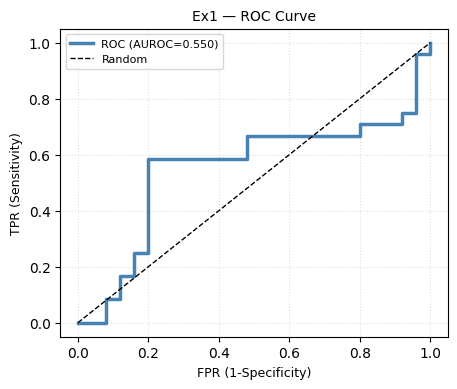

In [22]:
# Run the train pipeline
best_run = finalize(study, feat_train, feat_test)

### OOF-Platt: calibrate raw AE scores into honest probabilities

In [25]:
import torch
from sklearn.linear_model import LogisticRegression

def make_person_folds(feats, n_folds=2, seed=SEED):
    """Deterministic person-disjoint fold assignment (sorted before seeding)."""
    persons = sorted({f["person_id"] for f in feats})
    perm = np.random.default_rng(seed).permutation(len(persons))
    return [set(np.array(persons)[chunk].tolist())
            for chunk in np.array_split(perm, n_folds)]

def platt_fit_oof(study, feats, n_folds=2, verbose=True):
    """
    OOF-Platt for AE reconstruction scores:
      for each person-fold -> train a FRESH AE (best params) on the other
      folds' correct reps -> score the held-out reps -> collect (score,label)
      pairs that NO fold-AE ever saw its own training person in.
    Platt = 1-D logistic regression on log(score): raw reconstruction error
    is right-skewed and multiplicative, so the log makes the two class-
    conditionals much more logistic-shaped before fitting.
    Label convention follows your functions: 1 = PERFECT.
    """
    p = dict(study.best_params)
    folds = make_person_folds(feats, n_folds=n_folds)
    all_persons = sorted({f["person_id"] for f in feats})

    oof_s, oof_y = [], []
    for k, foldP in enumerate(folds):
        trP = set(all_persons) - foldP                       # person-disjoint
        coreP, holdP = (lambda ps: (set(ps[:int(len(ps)*0.85)]), set(ps[int(len(ps)*0.85):]))) (sorted(trP))
        Xc,  _, _ = collect(feats, persons=coreP, label=1)
        Xvc, _, _ = collect(feats, persons=holdP, label=1)
        scaler = FeatureScaler().fit(Xc)
        if len(Xvc):  s_model_trainer = scaler.transform(Xvc)
        set_seed(SEED + 100 + k)
        model, _ = train_ae(scaler.transform(Xc), p,
                        Xval_c=(scaler.transform(Xvc) if len(Xvc) else None),
                        seed=SEED + 100 + k)
        
        Xh, yh, _ = collect(feats, persons=foldP)            # BOTH classes needed
        s = ae_scores(model, scaler.transform(Xh), p["mask_ratio"])
        oof_s.append(s); oof_y.append(yh)
        if verbose:
            print(f"  fold {k+1}/{n_folds}: hold-out persons={len(foldP)} "
                  f"reps={len(yh)} (P={int(yh.sum())} / F={int((yh==0).sum())})")

    s = np.concatenate(oof_s); y = np.concatenate(oof_y)
    if len(np.unique(y)) < 2:
        raise RuntimeError("OOF set has a single class; cannot calibrate.")

    x = np.log(s + 1e-8).reshape(-1, 1)                      # log-space feature
    clf = LogisticRegression(C=1e4, max_iter=1000).fit(x, y) # 1= PERFECT (positive)
    a, b = float(clf.coef_[0][0]), float(clf.intercept_[0])
    if verbose:
        p_pass = clf.predict_proba(x)[:, 1]
        print(f"  Platt  a={a:.4f}  b={b:.4f}")
        print(f"  OOF sanity  AUROC(scores)={roc_auc_score(y, s):.3f}  "
              f"AUROC(Platt)={roc_auc_score(y, p_pass):.3f}  (identical by design)")
        print(f"  calibrated mean P(perfect): correct reps={p_pass[y==1].mean():.3f} "
              f"flawed reps={p_pass[y==0].mean():.3f}")
    return {"clf": clf, "eps": 1e-8, "a": a, "b": b, "n_folds": n_folds}

def platt_p_perfect(platt, s_err):
    """Raw AE score -> calibrated probability that the rep is PERFECT."""
    x = np.log(np.asarray(s_err) + platt["eps"]).reshape(-1, 1)
    return platt["clf"].predict_proba(x)[:, 1]

  fold 1/2: hold-out persons=5 reps=54 (P=27 / F=27)
  fold 2/2: hold-out persons=4 reps=46 (P=29 / F=17)
  Platt  a=0.0301  b=0.1081
  OOF sanity  AUROC(scores)=0.496  AUROC(Platt)=0.496  (identical by design)
  calibrated mean P(perfect): correct reps=0.561 flawed reps=0.559

  [Ex1] OOF-Platt calibrated test report
{'accuracy': 0.4898, 'balanced_acc': 0.5, 'precision': 0.4898, 'recall': 1.0, 'sensitivity': 1.0, 'specificity': 0.0, 'f1': 0.6575, 'f2': 0.8276, 'mcc': 0.0, 'auroc': 0.45, 'tp': 24, 'tn': 0, 'fp': 25, 'fn': 0}

  [Ex1-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     0 (  0.0%)      25 (100.0%)
  True FLAWED:      0 (  0.0%)      24 (100.0%)


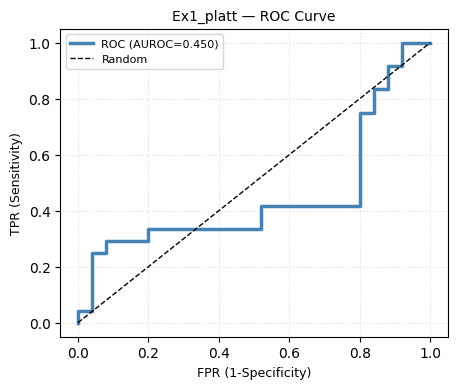

In [26]:
# apply the calibrated probabilities to the frozen test scores
def calibrate_run(best_run, study, feat_train, ex_name="Ex1"):
    platt  = platt_fit_oof(study, feat_train, n_folds=2)
    p_pass = platt_p_perfect(platt, best_run["scores"])       # aligns with best_run["y"]

    m = compute_all_metrics(best_run["y"],
                            (p_pass >= 0.5).astype(int),      # swappable with YOUR cut policy
                            p_pass)
    print(f"\n  [{ex_name}] OOF-Platt calibrated test report")
    print({k: (round(v, 4) if isinstance(v, (int, float, np.floating)) else v)
           for k, v in m.items()})
    print_confusion_matrix(best_run["y"], (p_pass >= 0.5).astype(int),
                           f"{ex_name}-OOFPlatt")
    plot_roc_curve(best_run["y"], p_pass, f"{ex_name}_platt")
    best_run["platt"] = platt
    best_run["p_pass"] = p_pass
    return platt, p_pass

platt, p_pass = calibrate_run(best_run, study, feat_train)

### CorrectionBank (Nearest-correct-neighbour)

In [27]:
JN_R = {v: k for k, v in JN.items()}                          # index -> name

class CorrectionBank:
    """
    Nearest-correct-neighbour reference bank (final-configs personalization):
      personal bank  -> the patient's OWN correct reps (returning patient)
      global bank    -> all train-person correct reps    (first-visit patient)
    Similarity is measured in the trained AE's LATENT space, not raw 5040-d:
    the encoder already learned which feature combinations matter for form.
    """
    def __init__(self, feat_train, model=None, scaler=None):
        self.records = [f for f in feat_train if f["label"] == 1]
        self.model, self.scaler = model, scaler
        self.embs = self._embed([r["X2d"] for r in self.records])
        self.by_person = {}
        for rec, e in zip(self.records, self.embs):
            self.by_person.setdefault(rec["person_id"], []).append((e, rec))

    def _embed(self, Xs):
        X = np.stack([np.asarray(x, np.float32).ravel() for x in Xs])
        if self.model is None:
            return X                                          # no AE -> feature distance
        Xs = self.scaler.transform(X)
        with torch.no_grad():
            z = self.model.encoder(torch.tensor(Xs, device=DEVICE)).cpu().numpy()
        return z

    def query(self, rec):
        """Nearest correct template: personal bank first, global fallback."""
        q = self._embed([rec["X2d"]])[0]
        pool = self.by_person.get(rec["person_id"]) or \
               list(zip(self.embs, self.records))             # personal-first
        dists = np.array([np.linalg.norm(q - e) for e, _ in pool])
        i = int(np.argmin(dists))
        return pool[i][1], float(dists[i])

    def correct(self, rec):
        """Full correction packet for one (flagged-flawed) rep."""
        ref, dist = self.query(rec)
        delta = ref["template"] - rec["template"]              # (F,26,2), torso-units,
        return {                                              # frames already aligned
            "ref": ref, "distance": dist, "delta": delta,
            "per_joint_disp": np.linalg.norm(delta, axis=-1).mean(0),
        }

def bank_summary(corr, top_k=4):
    """Plain-language correction hint. NOTE: y grows DOWNWARD in the data,
    so 'delta_y < 0 at high frames' means 'your arm ends too LOW -> raise it'."""
    top = np.argsort(-corr["per_joint_disp"])[:top_k]
    disp, delta = corr["per_joint_disp"], corr["delta"]
    F = delta.shape[0]
    imax = int(np.argmax(np.linalg.norm(delta, axis=-1), axis=None) // delta.shape[1])
    print(f"  reference distance (latent space): {corr['distance']:.4f}")
    print(f"  peak mismatch around frame {imax}/{F} "
          f"({'late' if imax > F/2 else 'early' if imax < F/4 else 'mid'} phase)")
    for j in top:
        print(f"   joint {j:>2} ({JN_R[j]:<13}) mean offset={disp[j]:.3f} torso-units")

### Ghost Overlay

In [33]:
def _draw_skel(ax, P, color, lw=1.2, label=None, ls="-"):
    """
    Full-body skeleton. Upper-body bones draw thick and opaque (Ex1 focus:
    arms + shoulder girdle pop visually), legs & tip bones draw thinner and
    translucent so they're readable without stealing attention.
    """
    ax.scatter(P[:, 0], P[:, 1], s=10, c=color, zorder=3, label=label)
    emphasized = set(UPPER_BONES)
    for s, e in FULL_BONES:
        if (s, e) in emphasized:
            ax.plot([P[s, 0], P[e, 0]], [P[s, 1], P[e, 1]], c=color, lw=lw, ls=ls, zorder=2)
        else:
            ax.plot([P[s, 0], P[e, 0]], [P[s, 1], P[e, 1]], c=color, lw=0.7, ls=ls, alpha=0.45, zorder=1)

def plot_ghost_overlay(rec, corr, sel=None, top_k=4, save_path=SAVE_PATH, prefix="Ex1"):
    rep, ref = rec["template"], corr["ref"]["template"]
    F = rep.shape[0]
    sel = sel or [0, F // 4, F // 2, 3 * F // 4, F - 1]
    top = np.argsort(-corr["per_joint_disp"])[:top_k]

    # --- shared window over ALL drawn frames (rep + ghost), small margin ---
    frames = np.concatenate([rep[sel], ref[sel]], axis=0)          # (S,26,2)
    pad = 0.15
    x0, x1 = frames[:, :, 0].min(), frames[:, :, 0].max()
    y0, y1 = frames[:, :, 1].min(), frames[:, :, 1].max()
    xr, yr = (x1 - x0) or 1.0, (y1 - y0) or 1.0
    xlim, ylim = (x0 - pad * xr, x1 + pad * xr), (y0 - pad * yr, y1 + pad * yr)

    fig, axes = plt.subplots(1, len(sel), figsize=(3.1 * len(sel), 4.2))
    for ax, t in zip(np.atleast_1d(axes), sel):
        _draw_skel(ax, ref[t], "0.45", ls=":", label="ghost (correct ref)" if t == sel[0] else None)
        _draw_skel(ax, rep[t], "steelblue", label="performed rep" if t == sel[0] else None)
        for j in top:
            ax.annotate("", xy=ref[t, j], xytext=rep[t, j], arrowprops=dict(arrowstyle="->", lw=1.4, color="crimson"))
        ax.set_xlim(*xlim);
        ax.set_ylim(ylim[1], ylim[0])     # every panel, same window
        ax.set_aspect("equal")                     # 1 torso-unit x == 1 torso-unit y
        ax.set_title(f"frame {t}", fontsize=9); ax.axis("off")
    axes = np.atleast_1d(axes)
    axes[0].legend(fontsize=8, loc="lower left")
    fig.suptitle(f"{prefix} ghost overlay — {rec['person_id']} rep{rec['rep']} "
                 f"| latent dist={corr['distance']:.3f}", fontsize=10)
    fpath = os.path.join(save_path, f"{prefix}_ghost_{rec['person_id']}_rep{rec['rep']}.png")
    plt.savefig(fpath, dpi=110, bbox_inches="tight"); plt.close()
    display(IPImage(fpath))
    return fpath

worst-scoring test rep: 039 rep11 label=0 p_pass=0.523
  reference distance (latent space): 5.9006
  peak mismatch around frame 19/90 (early phase)
   joint 15 (RightHand_end) mean offset=1.777 torso-units
   joint 14 (RightHand    ) mean offset=1.411 torso-units
   joint 23 (RightFoot    ) mean offset=0.912 torso-units
   joint 10 (LeftHand_end ) mean offset=0.771 torso-units


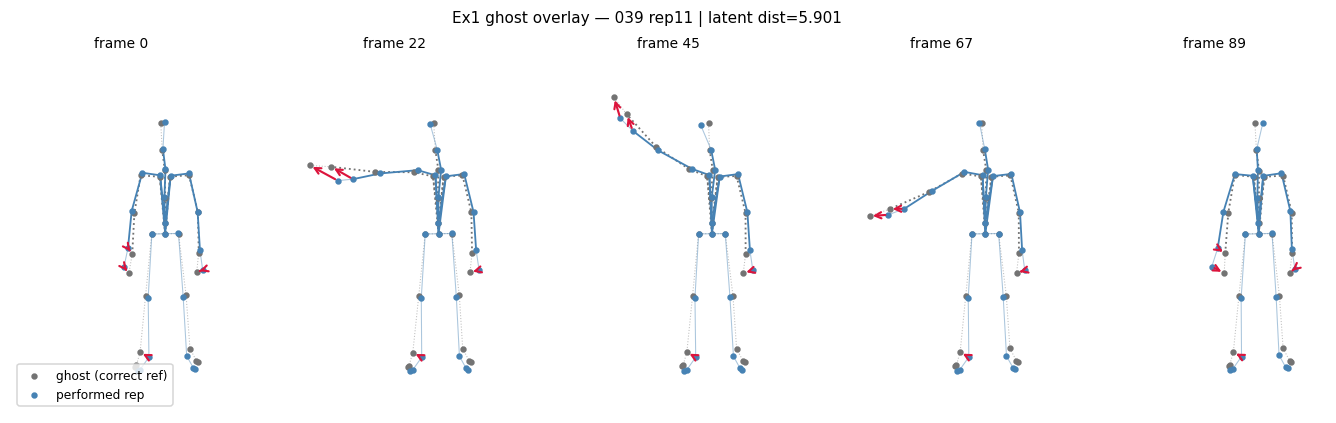

'/kaggle/working/Ex1_ghost_039_rep11.png'

In [34]:
bank = CorrectionBank(feat_train, model=best_run["model"], scaler=best_run["scaler"])

i = int(np.argmin(best_run["p_pass"]))                 # most-suspect test rep
rec = feat_test[i]                                     # same order as collect()
print(f"worst-scoring test rep: {rec['person_id']} rep{rec['rep']} "
      f"label={rec['label']} p_pass={best_run['p_pass'][i]:.3f}")

corr = bank.correct(rec)
bank_summary(corr)
plot_ghost_overlay(rec, corr, prefix="Ex1")

# Ex1 — Dynamic Masked AE: findings

**Findings**
- Val: ranking signal was promising (AUROC 0.839) but the pass/fail cut caught only 2/19 flawed reps (MCC 0.222).
- OOF + test: signal vanished — OOF AUROC 0.496, test AUROC 0.45–0.55, all 49 test reps predicted FAIL.
- Raw scores inverted: correct reps scored 349 vs flawed 83 — the opposite of what a form-grader should show.

**Reasons**
- Only ~9 train persons → the AE memorized *who* the training people are, so error measures "unknown person", not "bad form".
- With 19 val reps, most trials' threshold sideswiped everything → 39/40 trials scored a flat 0.0.